## 1. Imports

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device    : {DEVICE}")

PyTorch version : 2.11.0+cu128
CUDA available  : True
Using device    : cuda


## 2. Paths & config

In [3]:
PROJECT_DIR  = Path('/content/drive/MyDrive/uav_thesis')
DATA_VERSION = 'v5_voltage_kfold5'
DATA_ROOT    = PROJECT_DIR / 'processed_10hz' / 'v2'
OUTPUT_DIR   = PROJECT_DIR / 'model_outputs' / '04_lstm_bilstm_ae'
PLOT_DIR     = OUTPUT_DIR / 'plots'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = 'target_energy_next_60s_wh'
ID_COLS    = ['log_id', 'dataset_label']
FOLDS      = ['fold_01', 'fold_02', 'fold_03', 'fold_04', 'fold_05']

## 3. Model hyperparameters

Grounded in Reis & Reis (2025) — PX4 UAV LSTM-AE baseline.
hidden units scaled up from 32 → 64 to match 16-feature input dimensionality.

In [4]:

WINDOW_SIZE  = 100       # 10 seconds at 10 Hz
STRIDE       = 10        # sliding window step
HIDDEN_SIZE  = 64        # encoder hidden units
LATENT_SIZE  = 32        # bottleneck dimension
N_LAYERS     = 2         # LSTM layers in encoder and decoder
DROPOUT      = 0.2       # dropout between LSTM layers
BATCH_SIZE   = 64        # training batch size
LEARNING_RATE = 0.001    # Adam lr — directly from Reis et al. (2025)
MAX_EPOCHS   = 100       # max epochs before forced stop
PATIENCE     = 10        # early stopping patience on val loss
THRESHOLD_PCT = 95       # anomaly threshold percentile (normal train scores)

print(f"Data root  : {DATA_ROOT}")
print(f"Output     : {OUTPUT_DIR}")
print(f"Window     : {WINDOW_SIZE} rows  |  Stride: {STRIDE}")
print(f"Hidden     : {HIDDEN_SIZE}  |  Latent: {LATENT_SIZE}  |  Layers: {N_LAYERS}")

Data root  : /content/drive/MyDrive/uav_thesis/processed_10hz/v2
Output     : /content/drive/MyDrive/uav_thesis/model_outputs/04_lstm_bilstm_ae
Window     : 100 rows  |  Stride: 10
Hidden     : 64  |  Latent: 32  |  Layers: 2


## 4. Data loading

In [5]:
def load_fold_scaled(fold_name: str):
    """
    Load scaled train / val / test parquets for one fold.
    Uses the scaled version (no_dr_scaled_*) for LSTM/BiLSTM models.
    """
    fold_dir = DATA_ROOT / fold_name
    base     = f"no_dr_scaled_{DATA_VERSION}_{fold_name}"

    train_df = pd.read_parquet(fold_dir / f"train_{base}.parquet")
    val_df   = pd.read_parquet(fold_dir / f"val_{base}.parquet")
    test_df  = pd.read_parquet(fold_dir / f"test_{base}.parquet")

    return train_df, val_df, test_df


# quick sanity check
train_df, val_df, test_df = load_fold_scaled("fold_01")
feature_cols = [
    c for c in train_df.columns
    if c not in ID_COLS + [TARGET_COL]
    and pd.api.types.is_numeric_dtype(train_df[c])
]

print(f"\nFold 01 check:")
print(f"  Train : {train_df.shape}  |  {train_df['log_id'].nunique()} flights")
print(f"  Val   : {val_df.shape}    |  {val_df['log_id'].nunique()} flights")
print(f"  Test  : {test_df.shape}   |  {test_df['log_id'].nunique()} flights")
print(f"  Features ({len(feature_cols)}): {feature_cols}")
N_FEATURES = len(feature_cols)


Fold 01 check:
  Train : (665216, 19)  |  113 flights
  Val   : (110878, 19)    |  20 flights
  Test  : (190831, 19)   |  34 flights
  Features (16): ['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s', 'is_idle', 'power_w_rolling_std_3s', 'voltage_per_cell', 'voltage_filtered_per_cell', 'voltage_per_cell_suspicious']


## 5. Sliding window helper

In [6]:

def make_windows(df: pd.DataFrame, feature_cols: list,
                 window_size: int = WINDOW_SIZE,
                 stride: int = STRIDE,
                 normal_only: bool = False):
    """
    Create sliding windows from a flight-level dataframe.

    Windows are created per-flight to prevent cross-flight contamination.
    If normal_only=True, only rows from normal-labelled flights are windowed
    (used for training the autoencoder on clean data only).

    Returns
    -------
    X       : np.ndarray  shape (n_windows, window_size, n_features)
    log_ids : list of str — one log_id per window (from the last row of window)
    labels  : list of str — one dataset_label per window
    """
    X_list, id_list, label_list = [], [], []

    if normal_only:
        df = df[df["dataset_label"] == "normal"]

    for log_id, grp in df.groupby("log_id"):
        label = grp["dataset_label"].iloc[0]
        vals  = grp[feature_cols].values.astype(np.float32)

        if len(vals) < window_size:
            continue  # skip flights shorter than one window

        for start in range(0, len(vals) - window_size + 1, stride):
            X_list.append(vals[start : start + window_size])
            id_list.append(log_id)
            label_list.append(label)

    return np.array(X_list), id_list, label_list


# test windowing on fold_01 training set
X_test_win, _, _ = make_windows(train_df, feature_cols, normal_only=True)
print(f"\nWindowing check (normal train fold_01):")
print(f"  Windows : {X_test_win.shape}  →  (n_windows, {WINDOW_SIZE}, {N_FEATURES})")


Windowing check (normal train fold_01):
  Windows : (45884, 100, 16)  →  (n_windows, 100, 16)


## 6. Model definitions

In [7]:
class LSTMAutoencoder(nn.Module):
    """
    LSTM Autoencoder for multivariate time-series anomaly detection.

    Architecture:
        Encoder: N_LAYERS × LSTM(HIDDEN_SIZE) → linear bottleneck(LATENT_SIZE)
        Decoder: linear(LATENT_SIZE → HIDDEN_SIZE) → N_LAYERS × LSTM → output

    Trained on normal-only windows. Reconstruction MSE per window
    is used as the anomaly score at inference time.

    Reference:
        Reis & Reis (2025), Sensors 25(16), 4944.
        Malhotra et al. (2016), LSTM-based encoder-decoder for
        multi-sensor anomaly detection.
    """
    def __init__(self, n_features, hidden_size, latent_size, n_layers, dropout):
        super().__init__()
        self.n_features  = n_features
        self.hidden_size = hidden_size
        self.latent_size = latent_size
        self.n_layers    = n_layers

        # encoder
        self.encoder_lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.encoder_fc = nn.Linear(hidden_size, latent_size)

        # decoder
        self.decoder_fc   = nn.Linear(latent_size, hidden_size)
        self.decoder_lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.output_fc = nn.Linear(hidden_size, n_features)

    def forward(self, x):
        # x: (batch, seq_len, n_features)
        batch_size, seq_len, _ = x.size()

        # encode — take last timestep hidden state as context
        enc_out, _ = self.encoder_lstm(x)
        context     = self.encoder_fc(enc_out[:, -1, :])  # (batch, latent)

        # decode — repeat latent vector across sequence length
        dec_input = self.decoder_fc(context).unsqueeze(1).repeat(1, seq_len, 1)
        dec_out, _ = self.decoder_lstm(dec_input)
        recon       = self.output_fc(dec_out)             # (batch, seq_len, n_features)

        return recon


class BiLSTMAutoencoder(nn.Module):
    """
    Bidirectional LSTM Autoencoder for multivariate time-series anomaly detection.

    Architecture:
        Encoder: 1 × BiLSTM(HIDDEN_SIZE) — reads sequence in both directions
                 → linear bottleneck(LATENT_SIZE)
        Decoder: linear(LATENT_SIZE → HIDDEN_SIZE) → N_LAYERS × LSTM (unidirectional)
                 → output

    Decoder is unidirectional — bidirectional decoding is not meaningful
    for sequence reconstruction.

    Reference:
        Kim & Cho (2022), Smart Metering System Capable of Anomaly Detection
        by Bi-directional LSTM Autoencoder. arXiv:2112.03275.
        Kwon et al. (2019), GCN-BiLSTM autoencoder, AUC-ROC 0.961 vs
        LSTM-AE 0.940 on energy metering data.
    """
    def __init__(self, n_features, hidden_size, latent_size, n_layers, dropout):
        super().__init__()
        self.n_features  = n_features
        self.hidden_size = hidden_size
        self.latent_size = latent_size

        # bidirectional encoder — output is hidden_size*2
        self.encoder_lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=1,           # single BiLSTM layer
            batch_first=True,
            bidirectional=True,
            dropout=0.0
        )
        self.encoder_fc = nn.Linear(hidden_size * 2, latent_size)

        # unidirectional decoder
        self.decoder_fc   = nn.Linear(latent_size, hidden_size)
        self.decoder_lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )
        self.output_fc = nn.Linear(hidden_size, n_features)

    def forward(self, x):
        batch_size, seq_len, _ = x.size()

        # encode bidirectionally
        enc_out, _ = self.encoder_lstm(x)   # (batch, seq, hidden*2)
        context     = self.encoder_fc(enc_out[:, -1, :])  # (batch, latent)

        # decode unidirectionally
        dec_input = self.decoder_fc(context).unsqueeze(1).repeat(1, seq_len, 1)
        dec_out, _ = self.decoder_lstm(dec_input)
        recon       = self.output_fc(dec_out)

        return recon


print("Model classes defined: LSTMAutoencoder | BiLSTMAutoencoder")


Model classes defined: LSTMAutoencoder | BiLSTMAutoencoder


## 6. Training helpers

In [8]:

def train_autoencoder(model, train_loader, val_loader,
                      max_epochs=MAX_EPOCHS, patience=PATIENCE,
                      lr=LEARNING_RATE, fold_name="", model_name=""):
    """
    Train an autoencoder using MSE loss on normal-only windows.
    Early stopping on validation reconstruction loss.

    Parameters
    ----------
    model        : nn.Module — LSTMAutoencoder or BiLSTMAutoencoder
    train_loader : DataLoader of normal training windows
    val_loader   : DataLoader of normal validation windows
    max_epochs   : int
    patience     : int — stop if val loss does not improve for this many epochs
    lr           : float — Adam learning rate
    fold_name    : str — used for print labels
    model_name   : str — used for print labels

    Returns
    -------
    model         : trained nn.Module
    train_losses  : list of float
    val_losses    : list of float
    best_epoch    : int
    """
    model     = model.to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    train_losses, val_losses = [], []
    best_val_loss = float("inf")
    best_state    = None
    no_improve    = 0

    for epoch in range(1, max_epochs + 1):
        # ── training pass
        model.train()
        epoch_loss = 0.0
        for (xb,) in train_loader:
            xb = xb.to(DEVICE)
            optimiser.zero_grad()
            recon = model(xb)
            loss  = criterion(recon, xb)
            loss.backward()
            optimiser.step()
            epoch_loss += loss.item() * len(xb)
        epoch_loss /= len(train_loader.dataset)

        # ── validation pass
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for (xb,) in val_loader:
                xb    = xb.to(DEVICE)
                recon = model(xb)
                val_loss += criterion(recon, xb).item() * len(xb)
        val_loss /= len(val_loader.dataset)

        train_losses.append(epoch_loss)
        val_losses.append(val_loss)

        # ── early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state    = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve    = 0
            best_epoch    = epoch
        else:
            no_improve += 1

        if epoch % 10 == 0 or epoch == 1:
            print(f"  [{model_name} | {fold_name}] "
                  f"Epoch {epoch:3d}/{max_epochs} — "
                  f"train loss: {epoch_loss:.6f}  val loss: {val_loss:.6f}")

        if no_improve >= patience:
            print(f"  Early stop at epoch {epoch} "
                  f"(best val loss: {best_val_loss:.6f} @ epoch {best_epoch})")
            break

    # restore best weights
    model.load_state_dict(best_state)
    model.eval()
    return model, train_losses, val_losses, best_epoch


def compute_window_scores(model, X: np.ndarray, batch_size=256) -> np.ndarray:
    """
    Compute per-window MSE reconstruction error (anomaly score).

    Parameters
    ----------
    model      : trained nn.Module
    X          : np.ndarray shape (n_windows, window_size, n_features)
    batch_size : int

    Returns
    -------
    scores : np.ndarray shape (n_windows,) — MSE per window
    """
    model.eval()
    tensor  = torch.tensor(X, dtype=torch.float32)
    loader  = DataLoader(TensorDataset(tensor), batch_size=batch_size)
    scores  = []

    with torch.no_grad():
        for (xb,) in loader:
            xb    = xb.to(DEVICE)
            recon = model(xb)
            mse   = ((xb - recon) ** 2).mean(dim=(1, 2))  # per window
            scores.append(mse.cpu().numpy())

    return np.concatenate(scores)


def compute_flight_scores(window_scores: np.ndarray,
                          log_ids: list,
                          labels: list) -> pd.DataFrame:
    """
    Aggregate window-level scores to flight-level by taking the mean score
    per flight. Returns a DataFrame with one row per flight.

    Parameters
    ----------
    window_scores : np.ndarray shape (n_windows,)
    log_ids       : list of str — one per window
    labels        : list of str — one per window ("normal" / "abnormal")

    Returns
    -------
    pd.DataFrame with columns: log_id, dataset_label, mean_score, max_score
    """
    df = pd.DataFrame({
        "log_id"        : log_ids,
        "dataset_label" : labels,
        "score"         : window_scores,
    })
    flight_df = (
        df.groupby(["log_id", "dataset_label"])["score"]
        .agg(mean_score="mean", max_score="max")
        .reset_index()
    )
    return flight_df


def plot_loss_curves(train_losses, val_losses, fold_name, model_name, plot_dir):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(train_losses, label="Train loss", color="steelblue")
    ax.plot(val_losses,   label="Val loss",   color="tomato")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.set_title(f"Training Curves — {model_name} | {fold_name}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = model_name.lower().replace(" ", "_")
    plt.savefig(plot_dir / f"loss_{safe}_{fold_name}.png", dpi=150)
    plt.close()


def plot_score_distributions(normal_scores, test_scores, test_labels,
                             threshold, fold_name, model_name, plot_dir):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(normal_scores, bins=100, alpha=0.6,
            color="steelblue", label="Normal train scores", density=True)
    abn_mask = np.array(test_labels) == "abnormal"
    nrm_mask = ~abn_mask
    if nrm_mask.sum() > 0:
        ax.hist(test_scores[nrm_mask], bins=100, alpha=0.5,
                color="green", label="Test normal scores", density=True)
    if abn_mask.sum() > 0:
        ax.hist(test_scores[abn_mask], bins=100, alpha=0.5,
                color="red", label="Test abnormal scores", density=True)
    ax.axvline(threshold, color="black", linestyle="--",
               linewidth=1.5, label=f"Threshold (p{THRESHOLD_PCT})")
    ax.set_xlabel("Reconstruction MSE")
    ax.set_ylabel("Density")
    ax.set_title(f"Score Distributions — {model_name} | {fold_name}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = model_name.lower().replace(" ", "_")
    plt.savefig(plot_dir / f"scores_{safe}_{fold_name}.png", dpi=150)
    plt.close()


print("Training helpers defined ✓")

Training helpers defined ✓


## 7. Main fold loop

In [9]:
all_results = []

MODEL_CONFIGS = [
    ("LSTM-AE",   LSTMAutoencoder),
    ("BiLSTM-AE", BiLSTMAutoencoder),
]

for fold_name in FOLDS:
    print(f"\n{'='*70}")
    print(f"FOLD: {fold_name}")
    print(f"{'='*70}")

    # load scaled data
    train_df, val_df, test_df = load_fold_scaled(fold_name)

    feature_cols = [
        c for c in train_df.columns
        if c not in ID_COLS + [TARGET_COL]
        and pd.api.types.is_numeric_dtype(train_df[c])
    ]
    N_FEATURES = len(feature_cols)

    # build windows
    X_train, train_ids, train_labels = make_windows(train_df, feature_cols, normal_only=True)
    X_val_norm, val_ids_norm, val_labels_norm = make_windows(val_df, feature_cols, normal_only=True)
    X_test, test_ids, test_labels = make_windows(test_df, feature_cols, normal_only=False)

    print(f"  Windows — Train (normal): {X_train.shape}")
    print(f"  Windows — Val  (normal): {X_val_norm.shape}")
    print(f"  Windows — Test (all)   : {X_test.shape}")

    train_loader = DataLoader(
        TensorDataset(torch.tensor(X_train, dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(torch.tensor(X_val_norm, dtype=torch.float32)),
        batch_size=BATCH_SIZE, shuffle=False
    )

    for model_name, ModelClass in MODEL_CONFIGS:

        # ── CHECKPOINT SKIP ──
        safe_name = model_name.lower().replace('-', '_')
        ckpt = OUTPUT_DIR / f'{safe_name}_{fold_name}.pt'
        if ckpt.exists():
            print(f'  Skipping {model_name} {fold_name} — checkpoint exists')
            continue

        print(f"\n  ── {model_name} ──────────────────────────────────")

        model = ModelClass(
            n_features=N_FEATURES, hidden_size=HIDDEN_SIZE,
            latent_size=LATENT_SIZE, n_layers=N_LAYERS, dropout=DROPOUT,
        )
        n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"  Trainable parameters: {n_params:,}")

        model, train_losses, val_losses, best_epoch = train_autoencoder(
            model, train_loader, val_loader,
            fold_name=fold_name, model_name=model_name
        )

        plot_loss_curves(train_losses, val_losses, fold_name, model_name, PLOT_DIR)

        train_scores = compute_window_scores(model, X_train)
        threshold    = float(np.percentile(train_scores, THRESHOLD_PCT))
        print(f"  Threshold (p{THRESHOLD_PCT}): {threshold:.6f}")

        test_scores = compute_window_scores(model, X_test)

        plot_score_distributions(
            train_scores, test_scores, test_labels,
            threshold, fold_name, model_name, PLOT_DIR
        )

        flight_df = compute_flight_scores(test_scores, test_ids, test_labels)
        flight_df["y_true"] = (flight_df["dataset_label"] == "abnormal").astype(int)
        auroc = roc_auc_score(flight_df["y_true"], flight_df["mean_score"])

        normal_flight_mae   = flight_df[flight_df["dataset_label"]=="normal"]["mean_score"].mean()
        abnormal_flight_mae = flight_df[flight_df["dataset_label"]=="abnormal"]["mean_score"].mean()

        pred_anomaly  = (test_scores > threshold).astype(int)
        true_anomaly  = (np.array(test_labels) == "abnormal").astype(int)
        window_tp     = ((pred_anomaly == 1) & (true_anomaly == 1)).sum()
        window_fp     = ((pred_anomaly == 1) & (true_anomaly == 0)).sum()
        window_tn     = ((pred_anomaly == 0) & (true_anomaly == 0)).sum()
        window_fn     = ((pred_anomaly == 0) & (true_anomaly == 1)).sum()
        window_recall = window_tp / (window_tp + window_fn + 1e-9)
        window_fpr    = window_fp / (window_fp + window_tn + 1e-9)

        print(f"\n  RESULTS — {model_name} | {fold_name}")
        print(f"    AUROC      : {auroc:.4f}")
        print(f"    Normal     : {normal_flight_mae:.6f}")
        print(f"    Abnormal   : {abnormal_flight_mae:.6f}")
        print(f"    Recall@p95 : {window_recall:.4f}")
        print(f"    FPR@p95    : {window_fpr:.4f}")
        print(f"    Best epoch : {best_epoch}")

        torch.save(model.state_dict(), OUTPUT_DIR / f"{safe_name}_{fold_name}.pt")

        flight_df["fold"]      = fold_name
        flight_df["model"]     = model_name
        flight_df["threshold"] = threshold
        flight_df.to_parquet(OUTPUT_DIR / f"flight_scores_{safe_name}_{fold_name}.parquet", index=False)

        pd.DataFrame({
            "log_id": test_ids, "dataset_label": test_labels,
            "score": test_scores, "pred_anomaly": pred_anomaly,
        }).to_parquet(OUTPUT_DIR / f"window_scores_{safe_name}_{fold_name}.parquet", index=False)

        all_results.append({
            "fold": fold_name, "model": model_name,
            "auroc": round(auroc, 4),
            "mean_score_normal": round(normal_flight_mae, 6),
            "mean_score_abnormal": round(abnormal_flight_mae, 6),
            "score_ratio": round(abnormal_flight_mae / (normal_flight_mae + 1e-9), 4),
            "threshold": round(threshold, 6),
            "window_recall": round(window_recall, 4),
            "window_fpr": round(window_fpr, 4),
            "best_epoch": best_epoch,
            "n_train_windows": len(X_train),
            "n_test_windows": len(X_test),
            "n_test_flights": flight_df["log_id"].nunique(),
            "n_abnormal_flights": (flight_df["dataset_label"]=="abnormal").sum(),
            "n_params": n_params,
        })

        # save partial results after every model
        pd.DataFrame(all_results).to_parquet(OUTPUT_DIR / 'results_partial.parquet', index=False)
        print(f"  {model_name} {fold_name} complete ✓")

print(f"\n{'='*70}")
print("ALL 5 FOLDS × 2 MODELS COMPLETE")
print(f"{'='*70}")


FOLD: fold_01
  Windows — Train (normal): (45884, 100, 16)
  Windows — Val  (normal): (8757, 100, 16)
  Windows — Test (all)   : (18762, 100, 16)
  Skipping LSTM-AE fold_01 — checkpoint exists
  Skipping BiLSTM-AE fold_01 — checkpoint exists

FOLD: fold_02
  Windows — Train (normal): (46037, 100, 16)
  Windows — Val  (normal): (7178, 100, 16)
  Windows — Test (all)   : (21534, 100, 16)
  Skipping LSTM-AE fold_02 — checkpoint exists
  Skipping BiLSTM-AE fold_02 — checkpoint exists

FOLD: fold_03
  Windows — Train (normal): (46439, 100, 16)
  Windows — Val  (normal): (8471, 100, 16)
  Windows — Test (all)   : (18044, 100, 16)
  Skipping LSTM-AE fold_03 — checkpoint exists
  Skipping BiLSTM-AE fold_03 — checkpoint exists

FOLD: fold_04
  Windows — Train (normal): (45016, 100, 16)
  Windows — Val  (normal): (9188, 100, 16)
  Windows — Test (all)   : (17818, 100, 16)
  Skipping LSTM-AE fold_04 — checkpoint exists
  Skipping BiLSTM-AE fold_04 — checkpoint exists

FOLD: fold_05
  Windows — T

## 8. Summary table

In [10]:
OUTPUT_DIR = Path('/content/drive/MyDrive/uav_thesis/model_outputs/04_lstm_bilstm_ae')
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f.name)

bilstm_ae_fold_01.pt
bilstm_ae_fold_02.pt
bilstm_ae_fold_03.pt
bilstm_ae_fold_04.pt
bilstm_ae_fold_05.pt
flight_scores_bilstm_ae_fold_01.parquet
flight_scores_bilstm_ae_fold_02.parquet
flight_scores_bilstm_ae_fold_03.parquet
flight_scores_bilstm_ae_fold_04.parquet
flight_scores_bilstm_ae_fold_05.parquet
flight_scores_lstm_ae_fold_01.parquet
flight_scores_lstm_ae_fold_02.parquet
flight_scores_lstm_ae_fold_03.parquet
flight_scores_lstm_ae_fold_04.parquet
flight_scores_lstm_ae_fold_05.parquet
lstm_ae_fold_01.pt
lstm_ae_fold_02.pt
lstm_ae_fold_03.pt
lstm_ae_fold_04.pt
lstm_ae_fold_05.pt
lstm_bilstm_ae_5fold_summary.csv
lstm_bilstm_ae_all_folds_results.csv
plots
results_partial.parquet
window_scores_bilstm_ae_fold_01.parquet
window_scores_bilstm_ae_fold_02.parquet
window_scores_bilstm_ae_fold_03.parquet
window_scores_bilstm_ae_fold_04.parquet
window_scores_bilstm_ae_fold_05.parquet
window_scores_lstm_ae_fold_01.parquet
window_scores_lstm_ae_fold_02.parquet
window_scores_lstm_ae_fold_03.parq

In [11]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path('/content/drive/MyDrive/uav_thesis/model_outputs/04_lstm_bilstm_ae')

results_df = pd.read_parquet(OUTPUT_DIR / 'results_partial.parquet')
print(f'Rows: {len(results_df)}')
print(results_df[['fold','model','auroc']].to_string())

Rows: 9
      fold      model   auroc
0  fold_01  BiLSTM-AE  0.5865
1  fold_02    LSTM-AE  0.4756
2  fold_02  BiLSTM-AE  0.4444
3  fold_03    LSTM-AE  0.6900
4  fold_03  BiLSTM-AE  0.6350
5  fold_04    LSTM-AE  0.4100
6  fold_04  BiLSTM-AE  0.3800
7  fold_05    LSTM-AE  0.8700
8  fold_05  BiLSTM-AE  0.8900


In [14]:
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score

OUTPUT_DIR = Path('/content/drive/MyDrive/uav_thesis/model_outputs/04_lstm_bilstm_ae')
DATA_ROOT  = Path('/content/drive/MyDrive/uav_thesis/processed_10hz/v2')
DATA_VERSION = 'v5_voltage_kfold5'
TARGET_COL = 'target_energy_next_60s_wh'
ID_COLS    = ['log_id', 'dataset_label']

# reload model
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = LSTMAutoencoder(n_features=16, hidden_size=64,
                        latent_size=32, n_layers=2, dropout=0.2)
model.load_state_dict(torch.load(OUTPUT_DIR / 'lstm_ae_fold_01.pt',
                                  map_location=DEVICE))
model.to(DEVICE)
model.eval()

# reload data
train_df, val_df, test_df = load_fold_scaled('fold_01')
feature_cols = [c for c in train_df.columns
                if c not in ID_COLS + [TARGET_COL]
                and pd.api.types.is_numeric_dtype(train_df[c])]

X_train, _, _            = make_windows(train_df, feature_cols, normal_only=True)
X_test, test_ids, test_labels = make_windows(test_df, feature_cols, normal_only=False)

# recompute scores
train_scores  = compute_window_scores(model, X_train)
test_scores   = compute_window_scores(model, X_test)
threshold     = float(np.percentile(train_scores, 95))

# window metrics
pred_anomaly  = (test_scores > threshold).astype(int)
true_anomaly  = (np.array(test_labels) == 'abnormal').astype(int)
window_tp = ((pred_anomaly==1)&(true_anomaly==1)).sum()
window_fp = ((pred_anomaly==1)&(true_anomaly==0)).sum()
window_tn = ((pred_anomaly==0)&(true_anomaly==0)).sum()
window_fn = ((pred_anomaly==0)&(true_anomaly==1)).sum()
window_recall = window_tp/(window_tp+window_fn+1e-9)
window_fpr    = window_fp/(window_fp+window_tn+1e-9)

# auroc from saved flight scores
flight_df = pd.read_parquet(OUTPUT_DIR / 'flight_scores_lstm_ae_fold_01.parquet')
flight_df['y_true'] = (flight_df['dataset_label'] == 'abnormal').astype(int)
auroc = roc_auc_score(flight_df['y_true'], flight_df['mean_score'])

normal_mean   = flight_df[flight_df['dataset_label']=='normal']['mean_score'].mean()
abnormal_mean = flight_df[flight_df['dataset_label']=='abnormal']['mean_score'].mean()

print(f'LSTM-AE fold_01 recomputed:')
print(f'  AUROC         : {auroc:.4f}')
print(f'  Normal mean   : {normal_mean:.6f}')
print(f'  Abnormal mean : {abnormal_mean:.6f}')
print(f'  Score ratio   : {abnormal_mean/normal_mean:.4f}')
print(f'  Threshold     : {threshold:.6f}')
print(f'  Recall@p95    : {window_recall:.4f}')
print(f'  FPR@p95       : {window_fpr:.4f}')

# add missing row
missing_row = pd.DataFrame([{
    'fold'                 : 'fold_01',
    'model'                : 'LSTM-AE',
    'auroc'                : round(auroc, 4),
    'mean_score_normal'    : round(normal_mean, 6),
    'mean_score_abnormal'  : round(abnormal_mean, 6),
    'score_ratio'          : round(abnormal_mean/(normal_mean+1e-9), 4),
    'threshold'            : round(threshold, 6),
    'window_recall'        : round(float(window_recall), 4),
    'window_fpr'           : round(float(window_fpr), 4),
    'best_epoch'           : 99,
    'n_test_flights'       : flight_df['log_id'].nunique(),
    'n_abnormal_flights'   : (flight_df['dataset_label']=='abnormal').sum(),
}])

results_df = pd.read_parquet(OUTPUT_DIR / 'results_partial.parquet')
results_df = pd.concat([missing_row, results_df], ignore_index=True)
results_df = results_df.sort_values(['fold','model']).reset_index(drop=True)

print(f'\nTotal rows: {len(results_df)}')
print(results_df[['fold','model','auroc','window_recall','window_fpr']].to_string())

# save complete
results_df.to_parquet(OUTPUT_DIR / 'results_partial.parquet', index=False)
results_df.to_csv(OUTPUT_DIR / 'lstm_bilstm_ae_all_folds_results.csv', index=False)
print('\nSaved.')

LSTM-AE fold_01 recomputed:
  AUROC         : 0.6394
  Normal mean   : 0.096045
  Abnormal mean : 0.414560
  Score ratio   : 4.3163
  Threshold     : 0.316028
  Recall@p95    : 0.3601
  FPR@p95       : 0.0409

Total rows: 10
      fold      model   auroc  window_recall  window_fpr
0  fold_01  BiLSTM-AE  0.5865         0.3304      0.0422
1  fold_01    LSTM-AE  0.6394         0.3601      0.0409
2  fold_02  BiLSTM-AE  0.4444         0.3426      0.1477
3  fold_02    LSTM-AE  0.4756         0.3404      0.1301
4  fold_03  BiLSTM-AE  0.6350         0.3779      0.0321
5  fold_03    LSTM-AE  0.6900         0.3689      0.0349
6  fold_04  BiLSTM-AE  0.3800         0.0072      0.1819
7  fold_04    LSTM-AE  0.4100         0.0036      0.1843
8  fold_05  BiLSTM-AE  0.8900         0.7893      0.1335
9  fold_05    LSTM-AE  0.8700         0.7836      0.1368

Saved.


In [18]:
results_df = pd.read_parquet(OUTPUT_DIR / 'results_partial.parquet')
results_df.to_csv(OUTPUT_DIR / "lstm_bilstm_ae_all_folds_results.csv", index=False)

print("\n5-FOLD MEAN ± STD — LSTM-AE vs BiLSTM-AE")
print("="*70)

summary = (
    results_df
    .groupby("model")[["auroc", "window_recall", "window_fpr",
                        "mean_score_normal", "mean_score_abnormal",
                        "score_ratio", "best_epoch"]]
    .agg(["mean", "std"])
    .round(4)
)
print(summary.to_string())
summary.to_csv(OUTPUT_DIR / "lstm_bilstm_ae_5fold_summary.csv")
flat = []
for model_name in results_df["model"].unique():
    sub = results_df[results_df["model"] == model_name]
    flat.append({
        "model"              : model_name,
        "AUROC mean"         : round(sub["auroc"].mean(), 4),
        "AUROC std"          : round(sub["auroc"].std(), 4),
        "Window recall mean" : round(sub["window_recall"].mean(), 4),
        "Window FPR mean"    : round(sub["window_fpr"].mean(), 4),
        "Score ratio mean"   : round(sub["score_ratio"].mean(), 4),
        "Best epoch mean"    : round(sub["best_epoch"].mean(), 1),
    })

flat_df = pd.DataFrame(flat).sort_values("AUROC mean", ascending=False).reset_index(drop=True)
flat_df.index += 1
print("\n--- FLAT SUMMARY (sorted by mean AUROC) ---")
print(flat_df.to_string())
flat_df.to_csv(OUTPUT_DIR / "lstm_bilstm_ae_flat_summary.csv", index=False)

print(f"\nBest model : {flat_df.iloc[0]['model']}")
print(f"Mean AUROC : {flat_df.iloc[0]['AUROC mean']:.4f} ± {flat_df.iloc[0]['AUROC std']:.4f}")


5-FOLD MEAN ± STD — LSTM-AE vs BiLSTM-AE
            auroc         window_recall         window_fpr         mean_score_normal         mean_score_abnormal         score_ratio            best_epoch         
             mean     std          mean     std       mean     std              mean     std                mean     std        mean        std       mean      std
model                                                                                                                                                              
BiLSTM-AE  0.5872  0.1983        0.3695  0.2783     0.1075  0.0667            0.1465  0.1008              5.3261  6.6733   33.435101  39.528198       49.4  38.2596
LSTM-AE    0.6170  0.1821        0.3713  0.2767     0.1054  0.0651            0.1683  0.1040              5.4172  6.6921   25.963800  27.156300       51.6  41.3739

--- FLAT SUMMARY (sorted by mean AUROC) ---
       model  AUROC mean  AUROC std  Window recall mean  Window FPR mean  Score ratio mean  B

## 9. Comparison bar chart

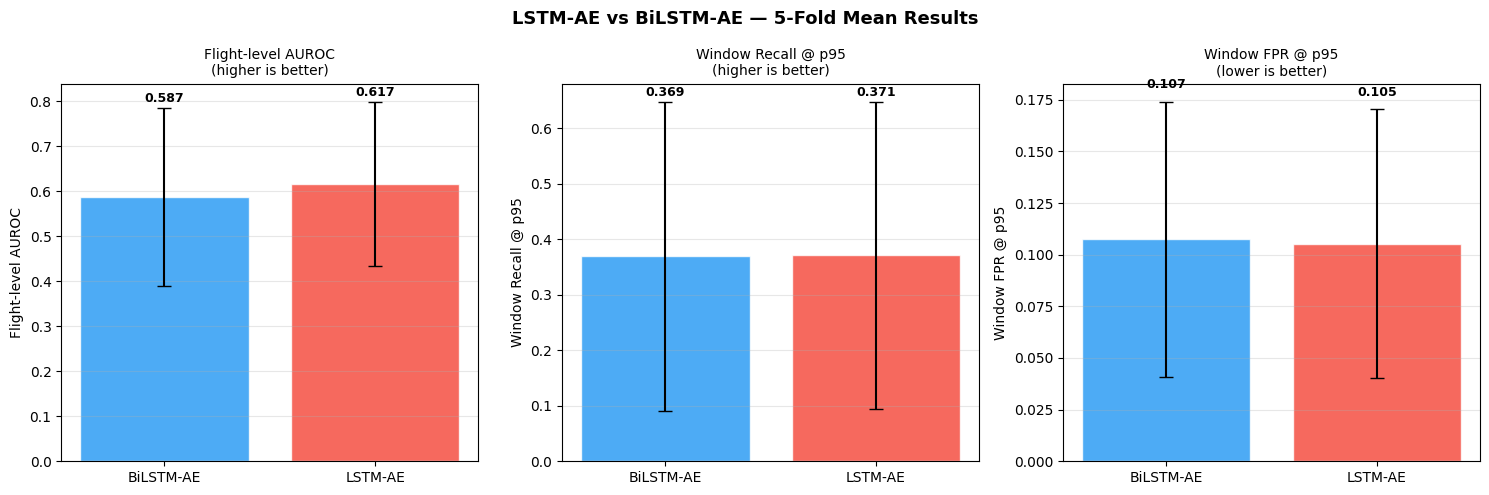


All outputs saved to: /content/drive/MyDrive/uav_thesis/model_outputs/04_lstm_bilstm_ae


In [19]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("LSTM-AE vs BiLSTM-AE — 5-Fold Mean Results", fontsize=13, fontweight="bold")

metrics = [
    ("auroc",          "Flight-level AUROC",   "higher is better"),
    ("window_recall",  "Window Recall @ p95",  "higher is better"),
    ("window_fpr",     "Window FPR @ p95",     "lower is better"),
]

colors = ["#2196F3", "#F44336"]

for ax, (metric, ylabel, note) in zip(axes, metrics):
    for i, model_name in enumerate(results_df["model"].unique()):
        sub  = results_df[results_df["model"] == model_name]
        mean = sub[metric].mean()
        std  = sub[metric].std()
        bar  = ax.bar(model_name, mean, yerr=std,
                      color=colors[i], alpha=0.8, capsize=5,
                      edgecolor="white")
        ax.text(i, mean + std + 0.005, f"{mean:.3f}",
                ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_title(f"{ylabel}\n({note})", fontsize=10)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(PLOT_DIR / "lstm_bilstm_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print(f"\nAll outputs saved to: {OUTPUT_DIR}")

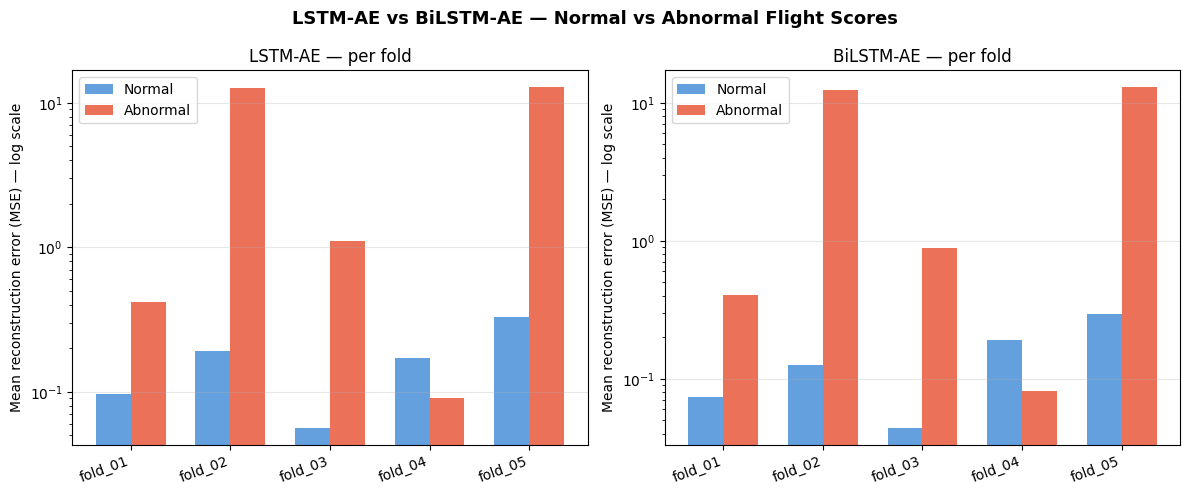

/tmp/ipykernel_702/620749527.py:42: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_702/620749527.py:42: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


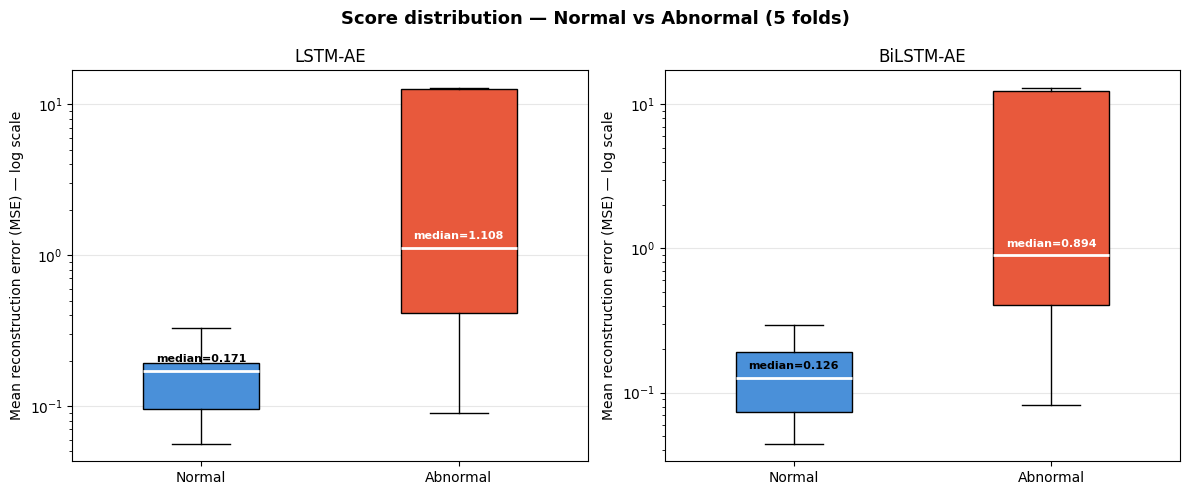


=== Median score ratio per model ===
LSTM-AE: mean ratio=25.96x  median ratio=19.62x
BiLSTM-AE: mean ratio=33.44x  median ratio=20.15x

Plots saved.


In [22]:
import numpy as np
import matplotlib.pyplot as plt

# ── Plot 1: per-fold bar chart with log scale ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("LSTM-AE vs BiLSTM-AE — Normal vs Abnormal Flight Scores",
             fontsize=13, fontweight="bold")

for ax, model_name in zip(axes, ['LSTM-AE', 'BiLSTM-AE']):
    sub        = results_df[results_df['model'] == model_name]
    folds      = sub['fold'].values
    x          = np.arange(len(folds))
    w          = 0.35
    norm_means = sub['mean_score_normal'].values
    abn_means  = sub['mean_score_abnormal'].values

    ax.bar(x - w/2, norm_means, w, color='#4A90D9', alpha=0.85, label='Normal')
    ax.bar(x + w/2, abn_means,  w, color='#E8593C', alpha=0.85, label='Abnormal')
    ax.set_yscale('log')
    ax.set_xticks(x)
    ax.set_xticklabels(folds, rotation=20, ha='right')
    ax.set_ylabel('Mean reconstruction error (MSE) — log scale')
    ax.set_title(f'{model_name} — per fold')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(PLOT_DIR / 'normal_vs_abnormal_scores_per_fold.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

# ── Plot 2: boxplot replacing global mean bar ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Score distribution — Normal vs Abnormal (5 folds)',
             fontsize=13, fontweight="bold")

for ax, model_name in zip(axes, ['LSTM-AE', 'BiLSTM-AE']):
    sub         = results_df[results_df['model'] == model_name]
    norm_scores = sub['mean_score_normal'].values
    abn_scores  = sub['mean_score_abnormal'].values

    bp = ax.boxplot(
        [norm_scores, abn_scores],
        labels=['Normal', 'Abnormal'],
        patch_artist=True, notch=False, widths=0.45
    )
    bp['boxes'][0].set_facecolor('#4A90D9')
    bp['boxes'][1].set_facecolor('#E8593C')
    for median in bp['medians']:
        median.set_color('white')
        median.set_linewidth(2)

    ax.set_yscale('log')
    ax.set_ylabel('Mean reconstruction error (MSE) — log scale')
    ax.set_title(f'{model_name}')
    ax.grid(True, alpha=0.3, axis='y')

    # median labels
    ax.text(1, np.median(norm_scores) * 1.15,
            f'median={np.median(norm_scores):.3f}',
            ha='center', fontsize=8, fontweight='bold')
    ax.text(2, np.median(abn_scores) * 1.15,
            f'median={np.median(abn_scores):.3f}',
            ha='center', fontsize=8, fontweight='bold', color='white')

plt.tight_layout()
plt.savefig(PLOT_DIR / 'score_boxplot_normal_vs_abnormal.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

# ── Plot 3: median score ratio per model ─────────────────────────────────────
print('\n=== Median score ratio per model ===')
for model_name in ['LSTM-AE', 'BiLSTM-AE']:
    sub          = results_df[results_df['model'] == model_name]
    median_ratio = (sub['mean_score_abnormal'] /
                   (sub['mean_score_normal'] + 1e-9)).median()
    mean_ratio   = sub['score_ratio'].mean()
    print(f'{model_name}: mean ratio={mean_ratio:.2f}x  median ratio={median_ratio:.2f}x')

print('\nPlots saved.')